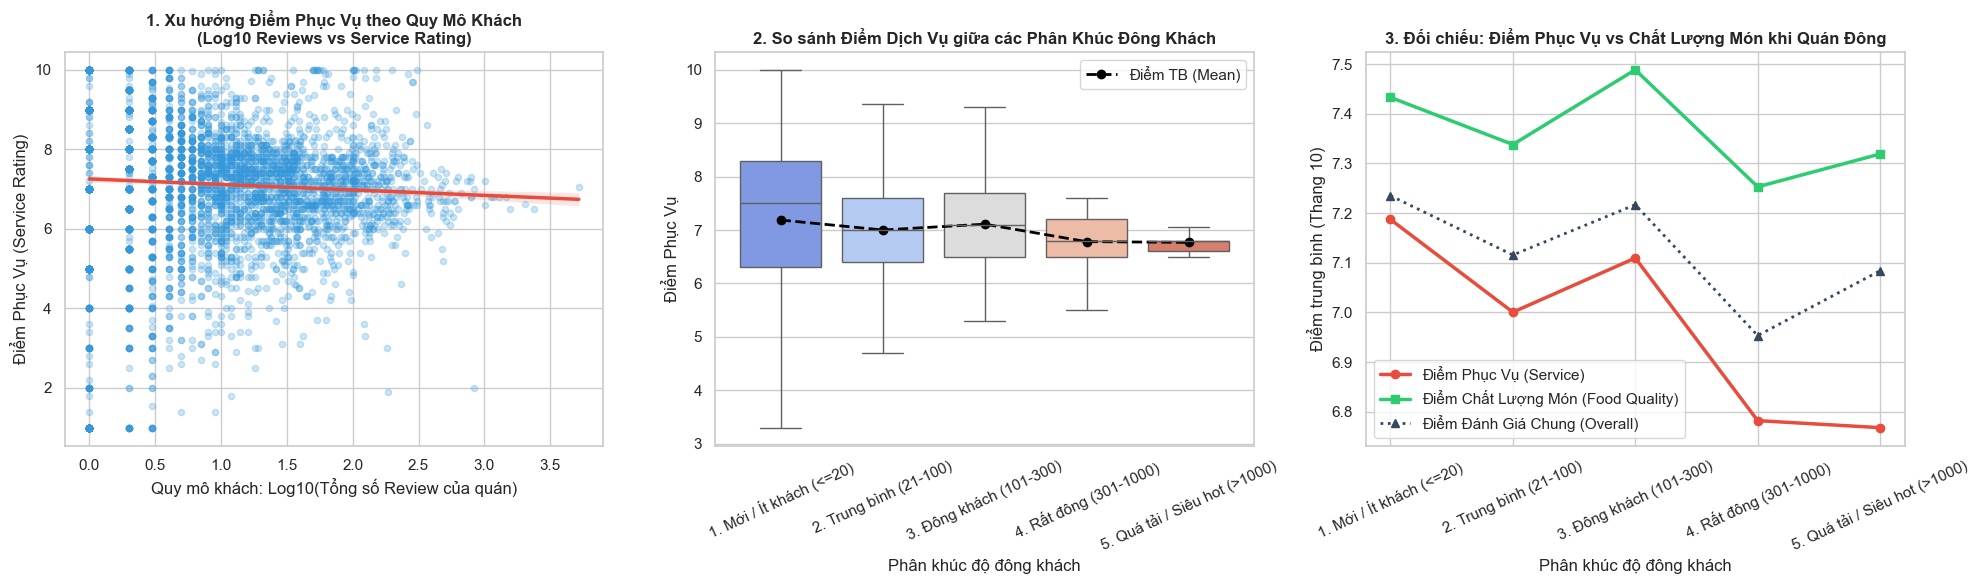

In [5]:
# ==========================================================
# CELL 5: VẼ BIỂU ĐỒ CHỨNG MINH XU HƯỚNG DỊCH VỤ KHI QUÁN ĐÔNG KHÁCH
# ==========================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Biểu đồ 1: Đường hồi quy (Regression Plot) giữa Log(Số lượng Review) và Điểm Phục Vụ
sns.regplot(
    data=clean_shops,
    x=np.log10(clean_shops["popularity_reviews"]),
    y="effective_service_score",
    scatter_kws={"alpha": 0.25, "color": "#3498db", "s": 20},
    line_kws={"color": "#e74c3c", "linewidth": 2.5},
    ax=axes[0]
)
axes[0].set_title("1. Xu hướng Điểm Phục Vụ theo Quy Mô Khách\n(Log10 Reviews vs Service Rating)", fontweight="bold")
axes[0].set_xlabel("Quy mô khách: Log10(Tổng số Review của quán)")
axes[0].set_ylabel("Điểm Phục Vụ (Service Rating)")

# Biểu đồ 2: Boxplot & Đường trung bình Điểm Phục Vụ qua 5 phân khúc đông khách
sns.boxplot(
    data=clean_shops,
    x="popularity_tier",
    y="effective_service_score",
    palette="coolwarm",
    showfliers=False,
    ax=axes[1]
)
means = clean_shops.groupby("popularity_tier", observed=False)["effective_service_score"].mean().values
axes[1].plot(range(len(means)), means, color="black", marker="o", linewidth=2, linestyle="--", label="Điểm TB (Mean)")
axes[1].set_title("2. So sánh Điểm Dịch Vụ giữa các Phân Khúc Đông Khách", fontweight="bold")
axes[1].set_xlabel("Phân khúc độ đông khách")
axes[1].set_ylabel("Điểm Phục Vụ")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()

# Biểu đồ 3: Sự dịch chuyển đồng thời của Điểm Dịch Vụ vs Điểm Chất Lượng Món Ăn
x_idx = range(len(trend_summary))
axes[2].plot(x_idx, trend_summary["diem_phuc_vu_tb"], marker="o", linewidth=2.5, color="#e74c3c", label="Điểm Phục Vụ (Service)")
axes[2].plot(x_idx, trend_summary["diem_chat_luong_mon"], marker="s", linewidth=2.5, color="#2ecc71", label="Điểm Chất Lượng Món (Food Quality)")
axes[2].plot(x_idx, trend_summary["diem_chung_tb"], marker="^", linewidth=2, linestyle=":", color="#34495e", label="Điểm Đánh Giá Chung (Overall)")
axes[2].set_xticks(x_idx)
axes[2].set_xticklabels(trend_summary["popularity_tier"], rotation=25)
axes[2].set_title("3. Đối chiếu: Điểm Phục Vụ vs Chất Lượng Món khi Quán Đông", fontweight="bold")
axes[2].set_xlabel("Phân khúc độ đông khách")
axes[2].set_ylabel("Điểm trung bình (Thang 10)")
axes[2].legend()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "q1_service_trend_analysis.png", dpi=300)
plt.show()

In [4]:
# ==========================================================
# CELL 4: PHÂN TÍCH CÂU HỎI 1 - TƯƠNG QUAN ĐỘ ĐÔNG KHÁCH & CHẤT LƯỢNG DỊCH VỤ
# ==========================================================

# 1. Gom nhóm dữ liệu theo từng quán (Shop-level Aggregation)
shop_df = df.groupby("shop_id").agg(
    shop_name=("shop_name", "first"),
    region=("region", "first"),
    city=("city", "first"),
    # Nếu quán có cột shop_total_review_count từ Foody thì lấy max, nếu null thì đếm số review thực tế trong dataset
    total_reviews=("shop_total_review_count", "max"),
    dataset_review_count=("review_id", "count"),
    avg_user_rating=("rating", "mean"),
    service_rating=("shop_service_rating", "mean"),
    quality_rating=("shop_quality_rating", "mean"),
    price_rating=("shop_price_rating", "mean"),
    bad_review_count=("shop_bad_review_count", "max")
).reset_index()

# Điền giá trị thiếu của total_reviews bằng số review thu thập được trong dataset
shop_df["popularity_reviews"] = shop_df["total_reviews"].fillna(shop_df["dataset_review_count"])
shop_df["popularity_reviews"] = np.maximum(shop_df["popularity_reviews"], shop_df["dataset_review_count"])

# Điểm dịch vụ đại diện: ưu tiên shop_service_rating, nếu trống lấy avg_user_rating
shop_df["effective_service_score"] = shop_df["service_rating"].fillna(shop_df["avg_user_rating"])

# Lọc các quán có dữ liệu hợp lệ
clean_shops = shop_df.dropna(subset=["popularity_reviews", "effective_service_score"]).copy()
clean_shops = clean_shops[clean_shops["popularity_reviews"] > 0]

# Tính tỷ lệ bình luận kém (%)
clean_shops["bad_review_ratio"] = (
    clean_shops["bad_review_count"].fillna(0) / clean_shops["popularity_reviews"]
).clip(0, 1) * 100

print(f"🔍 Tổng số quán ăn duy nhất (Unique Shops) đưa vào phân tích: {len(clean_shops):,} quán\n")

# 2. Phân chia quán thành 5 phân khúc độ đông khách (Popularity Tiers)
bins = [0, 20, 100, 300, 1000, np.inf]
labels = [
    "1. Mới / Ít khách (<=20)",
    "2. Trung bình (21-100)",
    "3. Đông khách (101-300)",
    "4. Rất đông (301-1000)",
    "5. Quá tải / Siêu hot (>1000)"
]
clean_shops["popularity_tier"] = pd.cut(clean_shops["popularity_reviews"], bins=bins, labels=labels)

# 3. Bảng tổng hợp xu hướng theo từng phân khúc
trend_summary = clean_shops.groupby("popularity_tier", observed=False).agg(
    so_luong_quan=("shop_id", "count"),
    diem_phuc_vu_tb=("effective_service_score", "mean"),
    diem_phuc_vu_median=("effective_service_score", "median"),
    diem_chat_luong_mon=("quality_rating", "mean"),
    diem_chung_tb=("avg_user_rating", "mean"),
    ty_le_review_kem_pct=("bad_review_ratio", "mean")
).reset_index()

display(trend_summary.style.format({
    "diem_phuc_vu_tb": "{:.2f}",
    "diem_phuc_vu_median": "{:.2f}",
    "diem_chat_luong_mon": "{:.2f}",
    "diem_chung_tb": "{:.2f}",
    "ty_le_review_kem_pct": "{:.2f}%"
}))

# 4. Kiểm định thống kê Pearson & Spearman
r_pearson, p_pearson = stats.pearsonr(np.log1p(clean_shops["popularity_reviews"]), clean_shops["effective_service_score"])
r_spearman, p_spearman = stats.spearmanr(clean_shops["popularity_reviews"], clean_shops["effective_service_score"])

print("=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ (STATISTICAL HYPOTHESIS TESTING) ===")
print(f"• Hệ số tương quan Pearson (Log Reviews vs Service Rating): r = {r_pearson:.4f} (p-value = {p_pearson:.4e})")
print(f"• Hệ số tương quan hạng Spearman (Reviews vs Service Rating): rho = {r_spearman:.4f} (p-value = {p_spearman:.4e})")

if p_spearman < 0.05:
    if r_spearman < 0:
        print("👉 KẾT LUẬN: Có bằng chứng thống kê rõ ràng (p < 0.05) cho thấy KHI QUÁN CÀNG ĐÔNG KHÁCH, ĐIỂM DỊCH VỤ CÓ XU HƯỚNG GIẢM XUỐNG!")
    else:
        print("👉 KẾT LUẬN: Có tương quan thuận có ý nghĩa thống kê (p < 0.05).")
else:
    print("👉 KẾT LUẬN: Sự suy giảm chưa có ý nghĩa thống kê tuyến tính đơn thuần, cần xem biểu đồ phân khúc chi tiết.")

🔍 Tổng số quán ăn duy nhất (Unique Shops) đưa vào phân tích: 5,223 quán



,popularity_tier,so_luong_quan,diem_phuc_vu_tb,diem_phuc_vu_median,diem_chat_luong_mon,diem_chung_tb,ty_le_review_kem_pct
0,1. Mới / Ít khách (<=20),3928,7.19,7.50,7.43,7.24,10.00%
1,2. Trung bình (21-100),950,7.00,7.00,7.34,7.12,10.48%
2,3. Đông khách (101-300),279,7.11,7.10,7.49,7.22,9.25%
3,4. Rất đông (301-1000),56,6.78,6.80,7.25,6.95,8.93%
4,5. Quá tải / Siêu hot (>1000),10,6.77,6.80,7.32,7.08,2.39%


=== KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ (STATISTICAL HYPOTHESIS TESTING) ===
• Hệ số tương quan Pearson (Log Reviews vs Service Rating): r = -0.0566 (p-value = 4.2832e-05)
• Hệ số tương quan hạng Spearman (Reviews vs Service Rating): rho = -0.1697 (p-value = 5.0050e-35)
👉 KẾT LUẬN: Có bằng chứng thống kê rõ ràng (p < 0.05) cho thấy KHI QUÁN CÀNG ĐÔNG KHÁCH, ĐIỂM DỊCH VỤ CÓ XU HƯỚNG GIẢM XUỐNG!


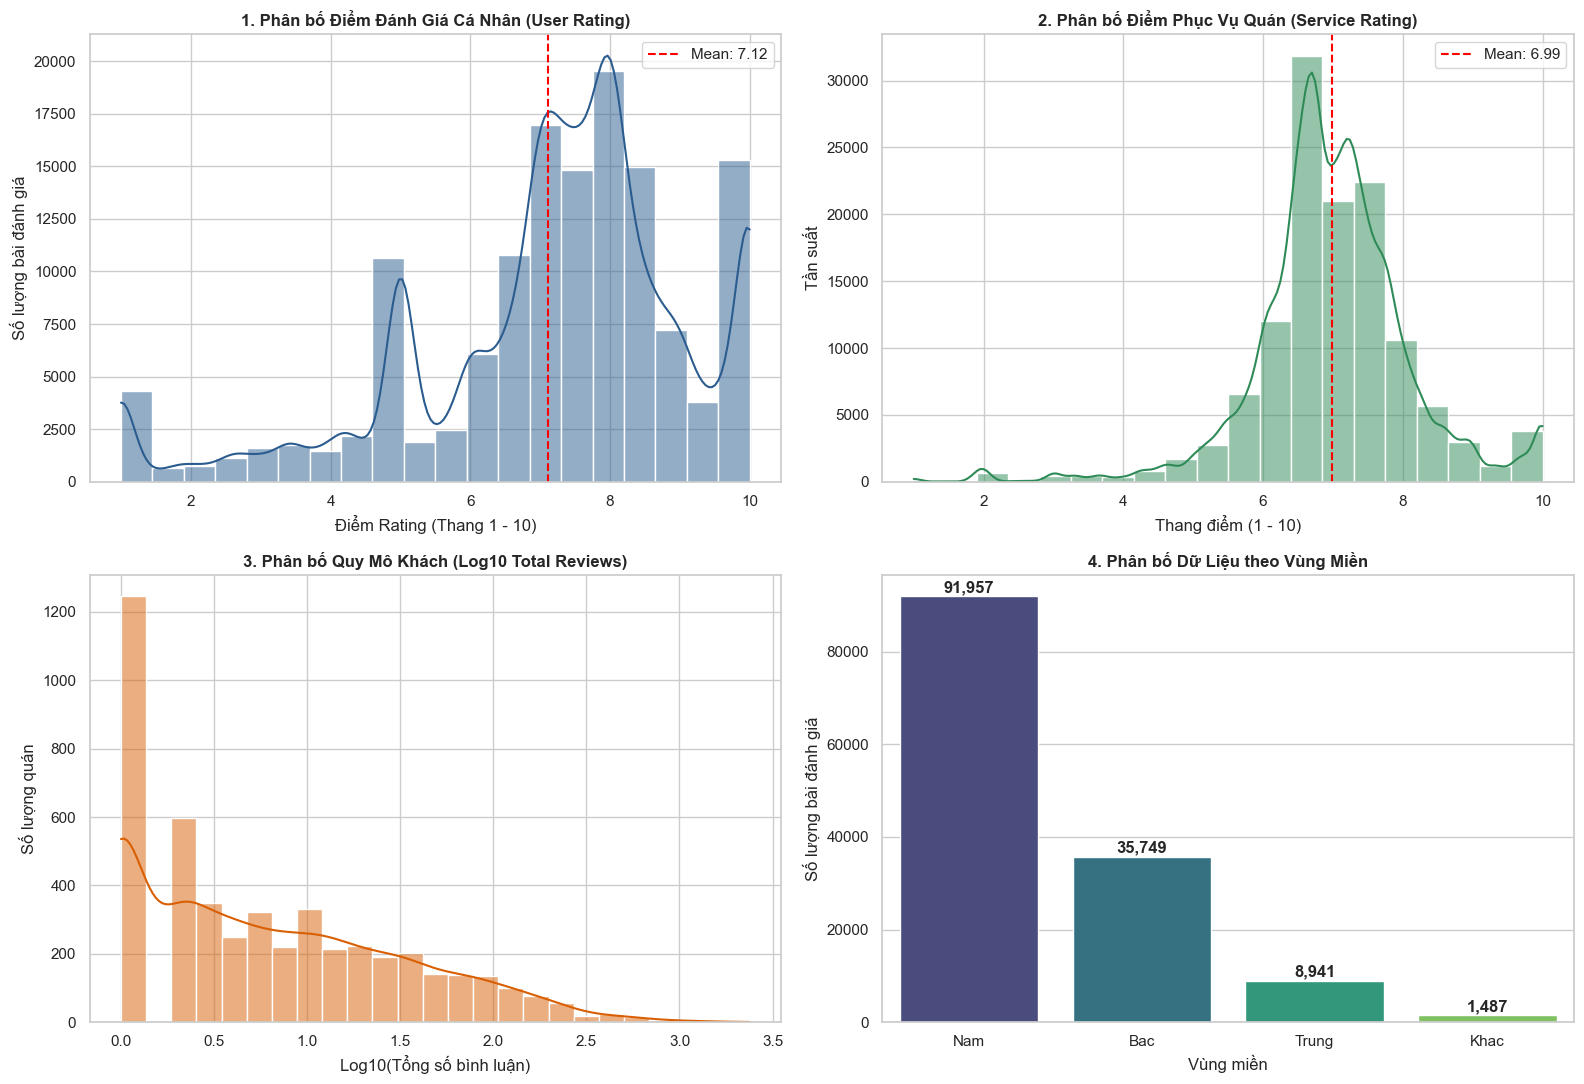

In [3]:
# ==========================================================
# CELL 3: VẼ BIỂU ĐỒ PHÂN BỐ (AN TOÀN TUYỆT ĐỐI)
# ==========================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Phân bố Điểm Đánh Giá Chung (User Rating)
sns.histplot(df["rating"].dropna(), bins=20, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].axvline(df["rating"].mean(), color="red", linestyle="--", label=f"Mean: {df['rating'].mean():.2f}")
axes[0, 0].set_title("1. Phân bố Điểm Đánh Giá Cá Nhân (User Rating)", fontweight="bold")
axes[0, 0].set_xlabel("Điểm Rating (Thang 1 - 10)")
axes[0, 0].set_ylabel("Số lượng bài đánh giá")
axes[0, 0].legend()

# 2. Phân bố Điểm Phục Vụ / Điểm Quán
col_service = "shop_service_rating" if df["shop_service_rating"].notnull().sum() > 0 else "shop_avg_rating"
lbl_service = "Điểm Phục Vụ Quán (Service Rating)" if col_service == "shop_service_rating" else "Điểm Trung Bình Quán (Shop Avg Rating)"
sns.histplot(df[col_service].dropna(), bins=20, kde=True, color="#2e8b57", ax=axes[0, 1])
axes[0, 1].axvline(df[col_service].mean(), color="red", linestyle="--", label=f"Mean: {df[col_service].mean():.2f}")
axes[0, 1].set_title(f"2. Phân bố {lbl_service}", fontweight="bold")
axes[0, 1].set_xlabel("Thang điểm (1 - 10)")
axes[0, 1].set_ylabel("Tần suất")
axes[0, 1].legend()

# 3. Phân bố Quy Mô Khách (Log10 Reviews)
col_reviews = "shop_total_review_count" if df["shop_total_review_count"].notnull().sum() > 0 else "shop_review_count"
valid_counts = df.groupby("shop_id")[col_reviews].first().dropna()
valid_counts = valid_counts[valid_counts > 0]
sns.histplot(np.log10(valid_counts), bins=25, kde=True, color="#d95f02", ax=axes[1, 0])
axes[1, 0].set_title("3. Phân bố Quy Mô Khách (Log10 Total Reviews)", fontweight="bold")
axes[1, 0].set_xlabel("Log10(Tổng số bình luận)")
axes[1, 0].set_ylabel("Số lượng quán")

# 4. Phân bố Vùng Miền
region_counts = df["region"].value_counts()
sns.barplot(x=region_counts.index, y=region_counts.values, palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("4. Phân bố Dữ Liệu theo Vùng Miền", fontweight="bold")
axes[1, 1].set_xlabel("Vùng miền")
axes[1, 1].set_ylabel("Số lượng bài đánh giá")
for i, v in enumerate(region_counts.values):
    axes[1, 1].text(i, v + (max(region_counts.values)*0.01), f"{v:,}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [2]:
# ==========================================================
# CELL 2: TỰ ĐỘNG KHỞI TẠO DATA DICTIONARY (TỪ ĐIỂN DỮ LIỆU)
# ==========================================================
column_descriptions = {
    "review_id": "Mã định danh duy nhất của bài đánh giá (Primary Key - MD5 Hash)",
    "shop_id": "Mã định danh của quán ăn/nhà hàng",
    "shop_name": "Tên quán ăn/nhà hàng (dạng slug chuẩn hóa)",
    "city": "Tỉnh/Thành phố nơi quán hoạt động",
    "region": "Phân vùng địa lý (Bac, Trung, Nam)",
    "user_name": "Tên tài khoản người dùng để lại đánh giá",
    "rating": "Điểm đánh giá chung của người dùng cho lần trải nghiệm (thang 1-10)",
    "review_photo_count": "Số lượng hình ảnh đính kèm trong bài đánh giá",
    "shop_position_rating": "Điểm đánh giá tiêu chí Vị trí của quán",
    "shop_price_rating": "Điểm đánh giá tiêu chí Giá cả của quán",
    "shop_quality_rating": "Điểm đánh giá tiêu chí Chất lượng món ăn",
    "shop_service_rating": "Điểm đánh giá tiêu chí Phục vụ (Dịch vụ) của quán",
    "shop_atmosphere_rating": "Điểm đánh giá tiêu chí Không gian quán",
    "shop_foody_avg_rating": "Điểm trung bình tổng thể của quán hiển thị trên hệ thống",
    "opening_time": "Giờ mở cửa của quán",
    "closing_time": "Giờ đóng cửa của quán",
    "min_price_vnd": "Mức giá thấp nhất (VNĐ)",
    "max_price_vnd": "Mức giá cao nhất (VNĐ)",
    "view_count": "Tổng số lượt xem trang của quán",
    "shop_total_review_count": "Tổng số lượng bình luận của quán trên Foody (độ đông khách)",
    "shop_excellent_review_count": "Số lượng bình luận xếp loại Tuyệt vời",
    "shop_good_review_count": "Số lượng bình luận xếp loại Khá tốt",
    "shop_average_review_count": "Số lượng bình luận xếp loại Trung bình",
    "shop_bad_review_count": "Số lượng bình luận xếp loại Kém",
    "device": "Thiết bị người dùng sử dụng để đăng đánh giá (iOS, Android, Web)",
    "comment_datetime": "Thời gian đăng bình luận (Ngày & Giờ)",
    "comment_hour": "Khung giờ đăng bình luận trong ngày (0 - 23h)",
    "day_of_week": "Thứ trong tuần đăng bình luận",
    "comment_text": "Nội dung văn bản chi tiết của bình luận",
    "comment_length_words": "Độ dài bình luận tính theo số từ",
    "comment_length_chars": "Độ dài bình luận tính theo số ký tự",
    "emoji_count": "Số lượng biểu tượng cảm xúc (Emoji) sử dụng trong bình luận",
    "num_reviews_by_user": "Tổng số bài đánh giá đã đóng góp bởi người dùng này",
    "source_platform": "Nền tảng nguồn thu thập (Foody / ShopeeFood)"
}

dict_rows = []
for col in df.columns:
    if col in ["teencode_score", "spelling_error_rate", "label_source", "crawl_timestamp"]:
        continue
    non_null = df[col].notnull().sum()
    null_pct = (df[col].isnull().sum() / len(df)) * 100
    sample_val = df[col].dropna().iloc[0] if non_null > 0 else "N/A"
    if isinstance(sample_val, str) and len(sample_val) > 40:
        sample_val = sample_val[:40] + "..."
        
    dict_rows.append({
        "Tên Trường (Column)": col,
        "Kiểu Dữ Liệu (Data Type)": str(df[col].dtype),
        "Tỷ Lệ Trống (% Null)": f"{null_pct:.2f}%",
        "Giá Trị Mẫu (Sample)": sample_val,
        "Ý Nghĩa / Mô Tả (Description)": column_descriptions.get(col, "Thuộc tính mở rộng")
    })

data_dictionary_df = pd.DataFrame(dict_rows)
display(data_dictionary_df)

# Xuất Data Dictionary ra file Excel/CSV để nộp kèm báo cáo
data_dictionary_df.to_csv(PROJECT_ROOT / "reports" / "Data_Dictionary_Report3.csv", index=False, encoding="utf-8-sig")

,Tên Trường (Column),Kiểu Dữ Liệu (Data Type),Tỷ Lệ Trống (% Null),Giá Trị Mẫu (Sample),Ý Nghĩa / Mô Tả (Description)
0,review_id,object,0.00%,1,Mã định danh duy nhất của bài đánh giá (Primar...
1,shop_id,int64,0.00%,90123314,Mã định danh của quán ăn/nhà hàng
2,shop_name,object,0.00%,Banh Canh Cua Ngo Khang De Tham,Tên quán ăn/nhà hàng (dạng slug chuẩn hóa)
3,city,object,0.00%,can-tho,Tỉnh/Thành phố nơi quán hoạt động
4,region,object,0.00%,Nam,"Phân vùng địa lý (Bac, Trung, Nam)"
5,user_name,object,0.00%,Phan V Hoà,Tên tài khoản người dùng để lại đánh giá
6,rating,float64,0.00%,1.0,Điểm đánh giá chung của người dùng cho lần trả...
7,review_photo_count,float64,41.78%,2.0,Số lượng hình ảnh đính kèm trong bài đánh giá
8,shop_position_rating,float64,9.18%,6.9,Điểm đánh giá tiêu chí Vị trí của quán
9,shop_price_rating,float64,9.18%,6.5,Điểm đánh giá tiêu chí Giá cả của quán


In [1]:
# ==========================================================
# CELL 1: KẾT NỐI POSTGRESQL & TẢI DỮ LIỆU ĐÃ LÀM SẠCH
# ==========================================================
import os
import warnings
from pathlib import Path
from dotenv import load_dotenv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sqlalchemy import create_engine

warnings.filterwarnings("ignore")

# Cấu hình giao diện biểu đồ chuẩn báo cáo khoa học
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
sns.set_theme(style="whitegrid", palette="muted")

# 1. Tìm thư mục gốc và nạp biến môi trường từ .env
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

DB_USER = os.getenv("POSTGRES_USER", "postgres")
DB_PASS = os.getenv("POSTGRES_PASSWORD", "postgres")
DB_HOST = os.getenv("POSTGRES_HOST", "localhost")
DB_PORT = os.getenv("POSTGRES_PORT", "5432")
DB_NAME = os.getenv("POSTGRES_DB", "foody_db")

# 2. Kết nối PostgreSQL và đọc bảng public.foody_reviews
csv_backup_path = PROJECT_ROOT / "data" / "processed" / "reviews_clean.csv"
csv_backup_path.parent.mkdir(parents=True, exist_ok=True)

try:
    engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")
    query = "SELECT * FROM public.foody_reviews;"
    df = pd.read_sql(query, engine)
    print(f"✅ Đã tải thành công {len(df):,} bản ghi trực tiếp từ PostgreSQL!")
    
    # Lưu bản backup CSV để phục vụ kiểm tra độc lập
    df.to_csv(csv_backup_path, index=False, encoding="utf-8-sig")
    print(f"📁 Đã lưu file dự phòng tại: {csv_backup_path}")
except Exception as e:
    print(f"⚠️ Không kết nối được PostgreSQL ({e}), chuyển sang đọc file CSV...")
    df = pd.read_csv(csv_backup_path)

# Hiển thị thông tin tổng quan
display(df.head(3))
df.info()

✅ Đã tải thành công 138,134 bản ghi trực tiếp từ PostgreSQL!
📁 Đã lưu file dự phòng tại: d:\ADY201m_Group4_Sentiment-Analysis\data\processed\reviews_clean.csv


,review_id,shop_id,shop_name,city,region,user_name,rating,review_photo_count,shop_position_rating,shop_price_rating,...,emoji_count,teencode_score,spelling_error_rate,num_reviews_by_user,label_source,source_platform,crawl_timestamp,shop_review_count,shop_avg_rating,updated_at
0,1,90123314,Banh Canh Cua Ngo Khang De Tham,can-tho,Nam,Phan V Hoà,1.0,2.0,6.9,6.5,...,0,None,None,1,human,Foody,2026-10-22 11:37:37.747264+00:00,26,6.453846,2026-10-22 11:37:47.673056+00:00
1,2,90123314,Banh Canh Cua Ngo Khang De Tham,can-tho,Nam,Dĩ Ly An,7.2,1.0,6.9,6.5,...,0,None,None,4,human,Foody,2026-10-22 11:37:37.747264+00:00,26,6.453846,2026-10-22 11:37:47.673056+00:00
2,3,90123314,Banh Canh Cua Ngo Khang De Tham,can-tho,Nam,Tím,5.4,NaN,6.9,6.5,...,0,None,None,10,human,Foody,2026-10-22 11:37:37.747610+00:00,26,6.453846,2026-10-22 11:37:47.673056+00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138134 entries, 0 to 138133
Data columns (total 41 columns):
 #   Column                       Non-Null Count   Dtype              
---  ------                       --------------   -----              
 0   review_id                    138134 non-null  object             
 1   shop_id                      138134 non-null  int64              
 2   shop_name                    138134 non-null  object             
 3   city                         138134 non-null  object             
 4   region                       138134 non-null  object             
 5   user_name                    138134 non-null  object             
 6   rating                       138134 non-null  float64            
 7   review_photo_count           80426 non-null   float64            
 8   shop_position_rating         125450 non-null  float64            
 9   shop_price_rating            125450 non-null  float64            
 10  shop_quality_rating          125